# ACS (American Community Survey)

---
*The Census Bureau's yearly survey of US households.*

The project uses two Data Profiles of the 2018-2022 5-year release, downloaded as .zip from data.census.gov on 29 October 2026, with every US census tract (`GEOID`) as the filter. Found in `data/0_raw/1_3_acs/`:
- `ACSDP5Y2022.DP05.zip`: Demographic and Housing Estimates
- `ACSDP5Y2022.DP03.zip`: Selected Economic Characteristics


The columns the study uses are hand-selected on data.census.gov and renamed in `data/1_data_notebooks/1_3_acs/handmade/acs_select_col_rename.csv`:
- `census_code` finds each one in its raw file
- `renamed_as` is its name in the study
- `website_path` is its row on the website

<hr style="border:none; border-top:0.5px solid #999">

The notebook:
- builds the ACS tract table from the columns selected on data.census.gov
- cleans the values: `-` becomes missing
- checks whether ACS holds every TIGER tract
- a tool for reading the study's results: poverty and density, mean or median → <span style="color:yellow">poverty_density_tails.png</span>
- <span style="color:red">**saves**</span> `data/1_data_notebooks/1_3_acs/acs.parquet` (+ `acs.csv`): the ACS tract table

<hr style="border:none; border-top:0.5px solid #999">

**Design choices:** the published shares stay as they are (percent, one decimal); the age bands as DP05 publishes them

---
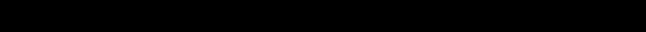

### Imports and setup

---
- Applies the shared plot style

In [1]:
import zipfile

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

from shared.paths import ACS_RAW_DIR, ACS_HANDMADE_DIR, TIGER_DIR, ACS_DIR, OUTPUTS_DIR
from shared.io_utils import write_parquet
from shared.plotting import setup_plotting, save_fig, PALETTE

setup_plotting()

OUT_DIR = OUTPUTS_DIR / "1_3_acs"

### Building the ACS tract table

---
Each selected column is found in its raw file by its Census code and renamed as the study calls it.
- each tract's `GEO_ID` is `1400000US` followed by the 11-digit id TIGER uses: the 11 digits are kept
- Puerto Rico (state 72) is left out: the study covers the 50 states and DC (following MPV)

In [2]:
selected = pd.read_csv(ACS_HANDMADE_DIR / "acs_select_col_rename.csv")
selected["profile"] = selected["census_code"].str[:4]  # DP05 or DP03: the zip the code sits in

columns = {}
for profile, profile_selection in selected.groupby("profile", sort=False):  # sort=False: the columns come out in the CSV's order
    with zipfile.ZipFile(ACS_RAW_DIR / f"ACSDP5Y2022.{profile}.zip") as zipped:
        # row 1 (the codes) becomes the header, row 2 (the website paths) is skipped
        # read as text, so every column takes the cleaning below
        data = pd.read_csv(zipped.open(f"ACSDP5Y2022.{profile}-Data.csv"), dtype=str, skiprows=[1])
    data["tract_id"] = data["GEO_ID"].str.removeprefix("1400000US")
    data = data[~data["tract_id"].str.startswith("72")]
    data = data.set_index("tract_id")  # the tract id as row name, so the two zips line up by tract
    for name, code in zip(profile_selection["renamed_as"], profile_selection["census_code"]):
        columns[name] = data[code]

acs = pd.DataFrame(columns).reset_index()

print(f"Tracts in the 50 states and DC: {len(acs):,}")

print(acs.head(3).T.to_string())

Tracts in the 50 states and DC: 84,415
                           0            1            2
tract_id         01001020100  01001020200  01001020300
total_pop               1865         1861         3492
pct_male                51.9         54.4         46.0
pct_female              48.1         45.6         54.0
pct_age_under_5          7.8          3.8          1.0
pct_age_5_9              9.8          3.7          5.2
pct_age_10_14            5.6          1.5         15.5
pct_age_15_19            3.4          4.5          7.9
pct_age_20_24            5.6          7.4          4.6
pct_age_25_34           11.6         22.5          9.4
pct_age_35_44           11.0         10.7         16.5
pct_age_45_54            8.5         13.3          9.3
pct_age_55_59           10.9          8.6         10.7
pct_age_60_64            6.4          8.4          6.4
pct_age_65_74            9.3         11.8          7.9
pct_age_75_84            7.2          2.2          4.0
pct_age_85_plus          2

### Cleaning

---
The Census enters `-` for:
- 0 residents
- the survey reached too few people for an estimate (the zip's Table-Notes)

No tract is dropped.

In [3]:
for name in acs.columns.drop("tract_id"):
    acs[name] = pd.to_numeric(acs[name].where(acs[name] != "-"))

### ACS and TIGER tract match

---

In [4]:
tracts = gpd.read_file(TIGER_DIR / "tracts.gpkg")

print(f"The files match: {set(tracts['tract_id']) == set(acs['tract_id'])}")

The files match: True


### Tails check → <span style="color:yellow">poverty_density_tails.png</span>

---
A long tail pulls a mean but not a median, so the data decides which one describes the two tract numbers the classes are described by: poverty, and population density.
- **Both have a long right tail** (skewness above 1): `pct_poverty` 1.8, `pop_density` 6.7
- the density panel stops at its 99th percentile: past it, the few densest tracts would squeeze every other bar into one

**Decision:** poverty and density are read through their median

                mean  median  skewness
pct_poverty    13.60   10.50       1.8
pop_density  2084.38  860.59       6.7


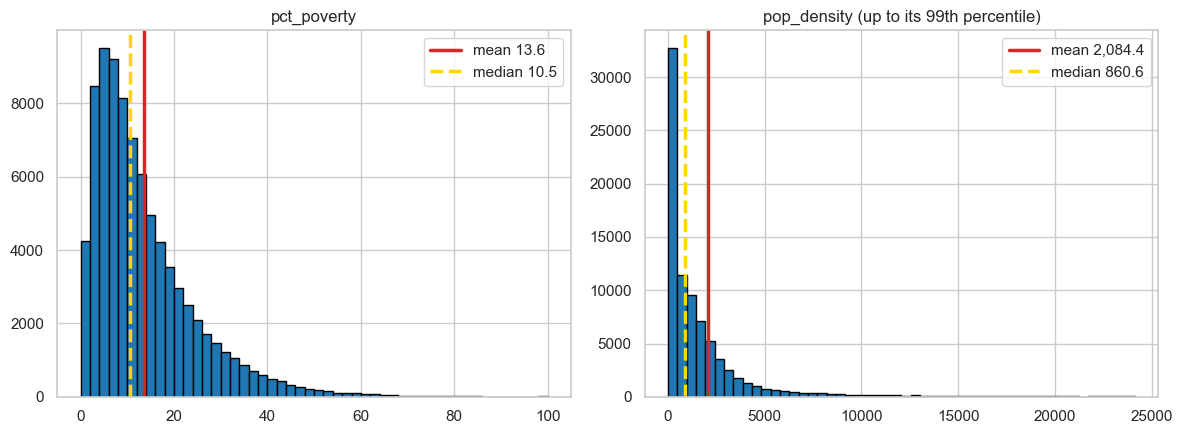

In [5]:
# density for the check only: residents per km² of land, a tract with 0 residents left empty
land_km2 = acs["tract_id"].map(tracts.set_index("tract_id")["tract_land_area"]) / 1_000_000  # m² -> km²
tract_numbers = pd.DataFrame({
    "pct_poverty": acs["pct_poverty"],
    "pop_density": acs["total_pop"].where(acs["total_pop"] > 0) / land_km2,
})

print(pd.DataFrame({
    "mean": tract_numbers.mean(),
    "median": tract_numbers.median(),
    "skewness": tract_numbers.skew(),
}).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, tract_numbers.columns):
    values = tract_numbers[name].dropna()
    shown = values[values <= values.quantile(0.99)] if name == "pop_density" else values
    ax.hist(shown, bins=50, color=PALETTE[0], edgecolor="black")
    ax.axvline(values.mean(), color=PALETTE[1], linewidth=2.5, label=f"mean {values.mean():,.1f}")
    ax.axvline(values.median(), color="gold", linewidth=2.5, linestyle="--", label=f"median {values.median():,.1f}")
    ax.set(title=name if name == "pct_poverty" else f"{name} (up to its 99th percentile)")
    ax.legend()
fig.tight_layout()
save_fig(fig, "poverty_density_tails", OUT_DIR)

### Save the ACS tract table

---

In [6]:
write_parquet(acs, ACS_DIR / "acs.parquet")
print(f"Saved data/1_data_notebooks/1_3_acs/acs.parquet + acs.csv: {acs.shape[0]:,} tracts × {acs.shape[1]} columns")

Saved data/1_data_notebooks/1_3_acs/acs.parquet + acs.csv: 84,415 tracts × 23 columns
